In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# upload do arquivo
df = pd.read_csv('WineQT.csv')

# remover a coluna ID para nao atrapalhar
df = df.drop(columns=['Id'])

# traduzir os nomes das colunas para facil entendivmento
df = df.rename(columns={
    'fixed acidity': 'acidez_fixa',
    'volatile acidity': 'acidez_volatil',
    'citric acid': 'acido_citrico',
    'residual sugar': 'acucar_residual',
    'chlorides': 'cloretos',
    'free sulfur dioxide': 'dioxido_enxofre_livre',
    'total sulfur dioxide': 'dioxido_enxofre_total',
    'density': 'densidade',
    'pH': 'ph',
    'sulphates': 'sulfatos',
    'alcohol': 'alcool'
})

# qualidade para binario
# alta qualidade (>= 7) = 1 | baixa/media qualidade (< 7) = 0
df['alvo_qualidade'] = (df['quality'] >= 7).astype(int)

# remover a coluna QUALITY para que o modelo nao tenha acesso a resposta original durante o treinamento, apenas o sistema binario
df = df.drop(columns=['quality'])

# exibir a porcentagem de vinhos de qualidade alta e baixa/media
print("Proporção das classes (0 = Qualidade Baixa/Média, 1 = Qualidade Alta):")
print(df['alvo_qualidade'].value_counts(normalize=True) * 100)

Proporção das classes (0 = Qualidade Baixa/Média, 1 = Qualidade Alta):
alvo_qualidade
0    86.089239
1    13.910761
Name: proportion, dtype: float64


# **Logo temos:**

*   *86,09%* de vinhos com qualidade baixa/média.
*   *13,91%* de vinhos com qualidade alta.

/tmp/ipykernel_1298/3792998194.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='alvo_qualidade', palette='viridis')


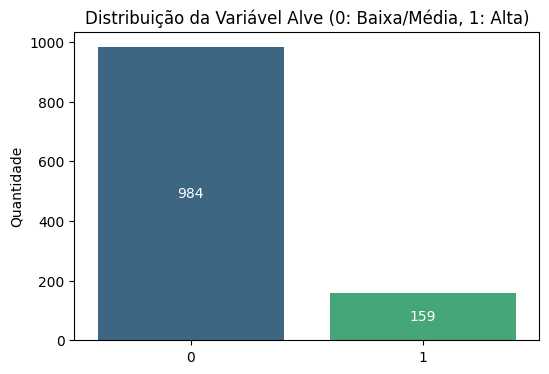

In [ ]:
# grafico 1: visualiar o desbalanciamento das classes
plt.figure(figsize=(6,4))
ax = sns.countplot(data=df, x='alvo_qualidade', palette='viridis')
plt.title('Distribuição da Variável Alve (0: Baixa/Média, 1: Alta)')
for container in ax.containers:
  ax.bar_label(container, label_type='center', color='white')
plt.ylabel('Quantidade')
plt.xlabel('')
plt.show()

**Gráfico 1:** Produzir um vinho de alta qualidade é um processo difícil e caro, dependendo da safra, clima e precisão na fermentação. A maioria dos vinhos são de qualidade baixa/média, e isso é um aviso, o nosso modelo ira ver muito mais exemplos de vinhos comuns do que excepcionais.

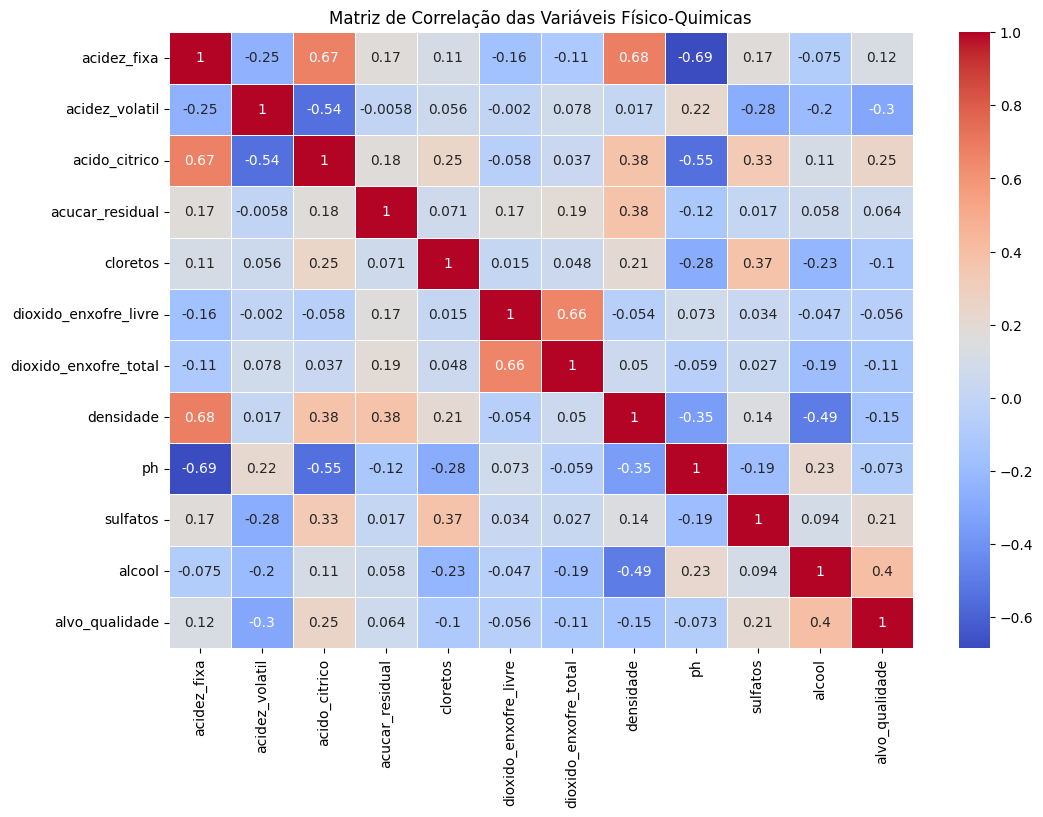

In [ ]:
# grafico 2: matriz de correlacao
plt.figure(figsize=(12,8))
correlacao_calc = df.corr()
sns.heatmap(correlacao_calc, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Matriz de Correlação das Variáveis Físico-Quimicas')
plt.show()

**Gráfico 2:** Aqui é mostrado o que "estraga" ou o o que "melhora" a nota do vinho de forma geral, podendo guiar quais varáveis os diretores das vinicolas devem monitorar mais de perto.

/tmp/ipykernel_1298/367300908.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='alvo_qualidade', y='alcool', ax=graficos[0], palette='Set2')
/tmp/ipykernel_1298/367300908.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='alvo_qualidade', y='acidez_volatil', ax=graficos[1], palette='Set2')


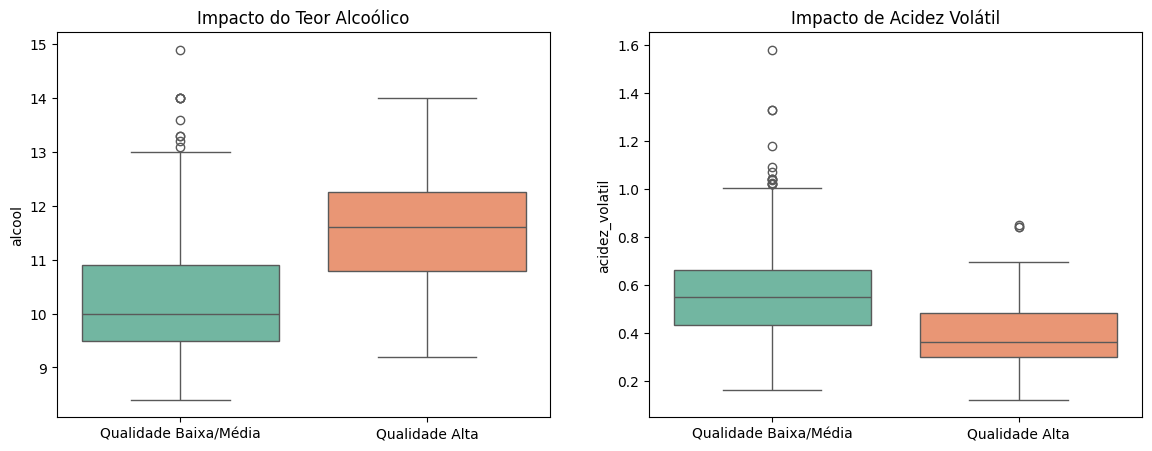

In [ ]:
# Grafico 3: impacto de varaveis especificas
fig, graficos = plt.subplots(1, 2, figsize=(14,5))
rotulos_x = ['Qualidade Baixa/Média', 'Qualidade Alta']

sns.boxplot(data=df, x='alvo_qualidade', y='alcool', ax=graficos[0], palette='Set2')
graficos[0].set_title('Impacto do Teor Alcoólico')
graficos[0].set_xticks([0,1])
graficos[0].set_xticklabels(rotulos_x)
graficos[0].set_xlabel('')

sns.boxplot(data=df, x='alvo_qualidade', y='acidez_volatil', ax=graficos[1], palette='Set2')
graficos[1].set_title('Impacto de Acidez Volátil')
graficos[1].set_xticks([0,1])
graficos[1].set_xticklabels(rotulos_x)
graficos[1].set_xlabel('')

plt.show()

**Gráfico 3:**


*   **Impacto do Teor Alcoólico:** O álcool é responsável por dar o "corpo" da
bebida, para dar aquela sensação de volume e textura na boca. Vinhos com pouco álcool podem aparecer "aguados" para os especiliastas, por isso teores mais altos tendem a receber notas melhores.
*   **Impacto de Acidez Volátil:** A acidez volátil mede, basicamente a quantidade e ácido acético na bebida. Em níveis altos, o vinho fica com cheiro e gosto de vinagre, indicando que bactérias indesejadas agiram durante a fermentação. É um defeito grave, por isso derruba a nota imediatamente.







In [ ]:
# preparando os dados
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# separador de tabela
X = df.drop(columns=['alvo_qualidade'])
y = df['alvo_qualidade']

# treino e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# padronização de escala
padronizador = StandardScaler()
X_treino_padronizado = padronizador.fit_transform(X_treino)
X_teste_padronizado = padronizador.transform(X_teste)

In [ ]:
# treinamento dos modelos
from sklearn.ensemble import RandomForestClassifier as rfc
from xgboost import XGBClassifier as xgbc

# modelo 1: random florest
florest = rfc(n_estimators=100, class_weight='balanced', random_state=42)
florest.fit(X_treino_padronizado, y_treino)

# modelo 2: XGBoost
peso_compensacao = y_treino.value_counts()[0] / y_treino.value_counts()[1]
xgboost = xgbc(eval_metric='logloss', scale_pos_weight=peso_compensacao, random_state=42)
xgboost.fit(X_treino_padronizado, y_treino)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

---Avaliação do Modelo: Random Florest---
              precision    recall  f1-score   support

           0       0.91      0.96      0.93       295
           1       0.59      0.40      0.47        48

    accuracy                           0.88       343
   macro avg       0.75      0.68      0.70       343
weighted avg       0.86      0.88      0.87       343

Nota ROC-AUC (capacidade de separar bons e ruins): 0.8592



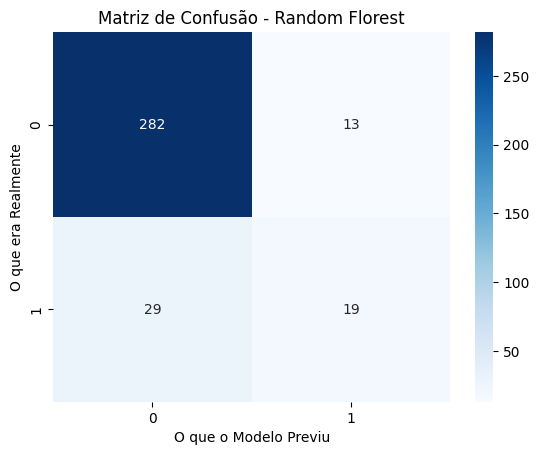

---Avaliação do Modelo: XGBoost---
              precision    recall  f1-score   support

           0       0.93      0.91      0.92       295
           1       0.49      0.56      0.52        48

    accuracy                           0.86       343
   macro avg       0.71      0.73      0.72       343
weighted avg       0.87      0.86      0.86       343

Nota ROC-AUC (capacidade de separar bons e ruins): 0.8230



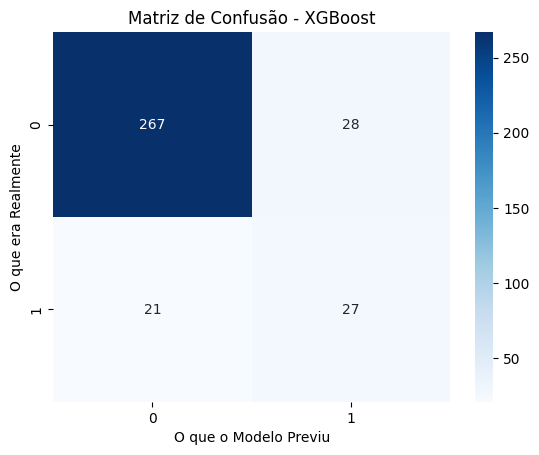

In [29]:
# avaliação dos modelos
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

def avaliar_modelo(modelo_treinado, nome_modelo):
  previsoes = modelo_treinado.predict(X_teste_padronizado)
  probabilidades = modelo_treinado.predict_proba(X_teste_padronizado)[:,1]

  print(f"---Avaliação do Modelo: {nome_modelo}---")
  print(classification_report(y_teste, previsoes))
  print(f"Nota ROC-AUC (capacidade de separar bons e ruins): {roc_auc_score(y_teste, probabilidades):.4f}\n")

  matriz = confusion_matrix(y_teste, previsoes)
  sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues')
  plt.title(f'Matriz de Confusão - {nome_modelo}')
  plt.xlabel('O que o Modelo Previu')
  plt.ylabel('O que era Realmente')
  plt.show()

avaliar_modelo(florest, "Random Florest")
avaliar_modelo(xgboost, "XGBoost")

/tmp/ipykernel_1298/3194990797.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importancia_das_colunas.values, y=importancia_das_colunas.index, palette='magma')


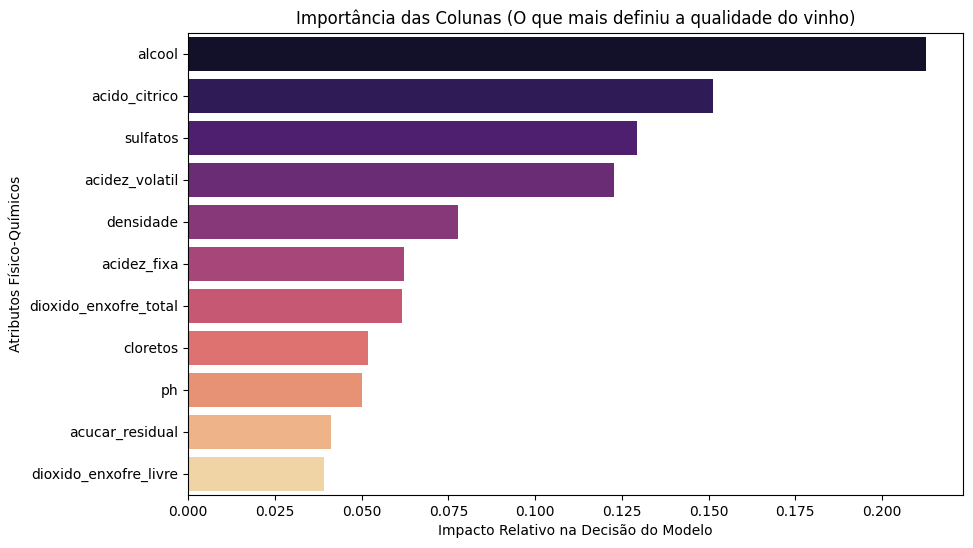

In [27]:
# Extração de Insights
importancia_das_colunas = pd.Series(
    florest.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=importancia_das_colunas.values, y=importancia_das_colunas.index, palette='magma')
plt.title('Importância das Colunas (O que mais definiu a qualidade do vinho)')
plt.xlabel('Impacto Relativo na Decisão do Modelo')
plt.ylabel('Atributos Físico-Químicos')
plt.show()